# ДЗ 1

**Датасет: Amazon Reviews 2023 (Software)**

**Головин Иван**


## 0. Запуск

- Создать виртуальное окружение питона и активировать его (`python3 -m venv .venv && source .venv/bin/activate`)

- установить зависимости (`pip install -r hw1/requirements.txt`)

- Выбрать в ноутбуке в качестве ядра питон из созданного окружения

- Запустить все блоки с кодом


В этом задании надо сравнить пять моделей, которые выдают персональные топ-10 приложений: ItemKNN, iALS, EASE, FM с метапризнаками и timeSVD++.

Взаимодействие - оценка, которую пользователь поставил товару, а релевантным считаем товар с оценкой 4 или 5.

Обучение долгое (на ноутбуке). Поэтому результаты полного запуска сохранены в `results`. При `TRAIN_MODELS = False`они показываются, при `True` модели обучаются заново.

In [ ]:
import gc
import json
import os
import pickle
from itertools import product
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import torch
from data_scripts.evaluation import (
    evaluation_report,
    ndcg_at_k,
    prepare_evaluation,
    ranking_metrics,
    recall_at_k,
)
from data_scripts.preparation import (
    chronological_split,
    filter_interactions,
    load_metadata,
    load_reviews,
)
from IPython.display import display
from models import EASE, FM, ImplicitALS, ItemKNN, TimeSVDpp

SEED = 67
K = 10
POSITIVE_RATING = 4  # минимальная оценка релевантного айтема
MIN_USER_REVIEWS = 5
MIN_ITEM_REVIEWS = 10
TUNING_USERS = (
    20_000  # на стольких пользователях сравниваем настройки (чтобы побыстрее было)
)
TRAIN_MODELS = True
N_THREADS = os.cpu_count()

DATA_DIR = Path("data")
RESULTS_DIR = Path("results")
MODEL_DIR = DATA_DIR / "results/models"

MODELS = {
    "ItemKNN": ItemKNN,
    "iALS": ImplicitALS,
    "EASE": EASE,
    "FM": FM,
    "timeSVD++": TimeSVDpp,
}
MODEL_NAMES = list(MODELS)
ABLATIONS = {  # чтобы узнать, как влияют метаданные
    "FM-ID": (FM, "FM", {"use_meta": False}),
    "SVD++-static": (TimeSVDpp, "timeSVD++", {"use_time": False}),
}

np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(N_THREADS)
pl.Config.set_tbl_rows(12)
pl.Config.set_tbl_cols(12)
DATA_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)
print("Polars:", pl.__version__)
print("Повторное обучение:", TRAIN_MODELS)

Рабочая папка: /home/neild/Projects/recsys/hw1
Polars: 2.0.0
Повторное обучение: True


## 1. Данные

Берём [Amazon Reviews 2023](https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023) с Hugging Face, только категорию software (в других категориях после отбора данных останется слишком мало юзеров / айтемов / взаимодействий).

В отзывах есть `user_id`, `parent_asin` (товар, в коде называю его `item_id`), `rating` (от 1 до 5) и `timestamp` (в миллисекундах).
У товаров есть ещё название, категории, описание и цена - они лежат в файле метаданных.

Файлы скачиваются из `raw/review_categories/Software.jsonl` и `raw/meta_categories/meta_Software.jsonl`.

Если они уже есть в `data`, повторно не качаются.

В Parquet сохраняются только нужные столбцы.

In [11]:
raw = load_reviews(DATA_DIR)
print("Исходных отзывов:", len(raw))
print("Пользователей:", raw["user_id"].n_unique())
print("Товаров:", raw["item_id"].n_unique())
display(raw.head())

parquet $data/Software_reviews.parquet exists, reading it
Исходных отзывов: 4880181
Пользователей: 2589466
Товаров: 89246


user_id,item_id,rating,timestamp
str,str,f64,f64
"""AGCI7FAH4GL5FI65HYLKWTMFZ2CQ""","""B0BQSK9QCF""",1.0,1.5622e12
"""AHSPLDNW5OOUK2PLH7GXLACFBZNQ""","""B00CTQ6SIG""",5.0,1.4241e12
"""AHSPLDNW5OOUK2PLH7GXLACFBZNQ""","""B0066WJLU6""",5.0,1.3624e12
"""AH6CATODIVPVUOJEWHRSRCSKAOHA""","""B00KCYMAWK""",4.0,1.5611e12
"""AEINY4XOINMMJCK5GZ3M6MMHBN6A""","""B00P1RK566""",4.0,1.4183e12


## 2. Первичный анализ

Сначала посмотрим на сырые данные: есть ли пропуски и повторы, как распределены оценки, сколько оценок ставят пользователи и насколько популярны товары. Для активности и популярности возьмём логарифмическую шкалу, иначе ничего не разглядеть: у нескольких товаров очень много оценок, но обычно единицы.

Пропуски (null):
shape: (1, 4)
┌─────────┬─────────┬────────┬───────────┐
│ user_id ┆ item_id ┆ rating ┆ timestamp │
│ ---     ┆ ---     ┆ ---    ┆ ---       │
│ u32     ┆ u32     ┆ u32    ┆ u32       │
╞═════════╪═════════╪════════╪═══════════╡
│ 0       ┆ 0       ┆ 0      ┆ 0         │
└─────────┴─────────┴────────┴───────────┘
NaN в оценке и времени:
shape: (1, 2)
┌────────┬───────────┐
│ rating ┆ timestamp │
│ ---    ┆ ---       │
│ u32    ┆ u32       │
╞════════╪═══════════╡
│ 0      ┆ 0         │
└────────┴───────────┘
Повторы пользователь-товар: 51701
Число оценок на пользователя:
shape: (9, 2)
┌────────────┬────────────┐
│ statistic  ┆ len        │
│ ---        ┆ ---        │
│ str        ┆ f64        │
╞════════════╪════════════╡
│ count      ┆ 2.589466e6 │
│ null_count ┆ 0.0        │
│ mean       ┆ 1.884628   │
│ std        ┆ 2.72006    │
│ min        ┆ 1.0        │
│ 50%        ┆ 1.0        │
│ 90%        ┆ 3.0        │
│ 99%        ┆ 12.0       │
│ max        ┆ 371.0      │

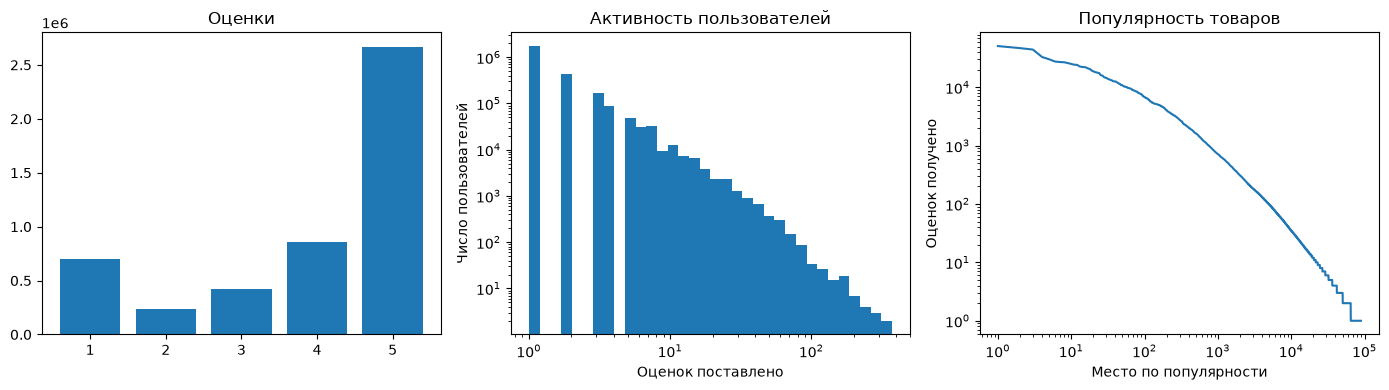

In [12]:
print("Пропуски (null):")
print(raw.null_count())
print("NaN в оценке и времени:")
print(raw.select(pl.col("rating", "timestamp").is_nan().sum()))
print(
    "Повторы пользователь-товар:",
    len(raw) - raw.select("user_id", "item_id").n_unique(),
)

per_user = raw.group_by("user_id").len()
per_item = raw.group_by("item_id").len().sort("len", descending=True)
rating_counts = raw.group_by("rating").len().sort("rating")
print("Число оценок на пользователя:")
print(per_user.select("len").describe(percentiles=[0.5, 0.9, 0.99]))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].bar(rating_counts["rating"].to_numpy(), rating_counts["len"].to_numpy())
axes[0].set(title="Оценки", xticks=[1, 2, 3, 4, 5])
axes[1].hist(
    per_user["len"].to_numpy(), bins=np.geomspace(1, per_user["len"].max() + 1, 35)
)
axes[1].set(
    xscale="log",
    yscale="log",
    title="Активность пользователей",
    xlabel="Оценок поставлено",
    ylabel="Число пользователей",
)
axes[2].loglog(np.arange(1, len(per_item) + 1), per_item["len"].to_numpy())
axes[2].set(
    title="Популярность товаров",
    xlabel="Место по популярности",
    ylabel="Оценок получено",
)
plt.tight_layout()
plt.show()

## 3. Очистка и уменьшение выборки

Сначала выкидываем битые строки: пустые id, оценку вне диапазона 1-5, некорректное время (вроде таких строк быть не должно, но мало ли).

Если пользователь оценил один товар несколько раз, оставляем последнюю оценку, а при одинаковом времени - большую.

Дальше по кругу убираем пользователей с менее чем 5 оценками и товары с менее чем 10, пока выборка не перестанет меняться (после удаления товаров у кого-то из пользователей может стать слишком мало оценок).

Порог для пользователей нужен, чтобы хватило истории для train, validation и test. Порог для товаров - чтобы у модели был хоть какой-то сигнал о каждом товаре. К тому же EASE хранит плотную матрицу "товар на товар", так что каталог должен помещаться в память. Случайно строки не удаляем. В конце проверяю размеры оставшегося датасета.

In [13]:
print(f"Изначально: {len(raw)}")

# битые строки
reviews = raw.with_columns(
    pl.col("rating").cast(pl.Float64, strict=False),
    pl.col("timestamp").cast(pl.Int64, strict=False),
)
reviews = reviews.drop_nulls().filter(
    pl.col("user_id") != "",
    pl.col("item_id") != "",
    pl.col("rating").is_between(1, 5),
    pl.col("rating").is_finite(),
    pl.col("timestamp").is_finite(),
    pl.col("timestamp") >= 0,
)
print(f"После удаления битых строк: {len(reviews)}")

# повторы
reviews = reviews.sort("user_id", "item_id", "timestamp", "rating", maintain_order=True)
reviews = reviews.unique(["user_id", "item_id"], keep="last", maintain_order=True)
reviews = reviews.with_columns(pl.col("timestamp").cast(pl.Int64))
print(f"После удаления повторов: {len(reviews)}")

# фильтр
selected = filter_interactions(reviews, MIN_USER_REVIEWS, MIN_ITEM_REVIEWS)
n_sel_users = selected["user_id"].n_unique()
n_sel_items = selected["item_id"].n_unique()

print(f"Итог: {len(selected)} отзывов, {n_sel_users} пользователей, {n_sel_items} товаров:")
print(f"Минимум оценок у пользователя {selected.group_by("user_id").len()["len"].min()}")
print(f"Минимум оценок у товара {selected.group_by("item_id").len()["len"].min()}")
print(f"Разреженность: {1 - len(selected) / (n_sel_users * n_sel_items)}")
print(
    "Период:",
    selected.select(
        pl.from_epoch(pl.col("timestamp").min(), time_unit="ms").alias("начало"),
        pl.from_epoch(pl.col("timestamp").max(), time_unit="ms").alias("конец"),
    ).row(0),
)

# требования
assert 100_000 <= len(selected) <= 2_000_000
assert n_sel_users >= 1000 and n_sel_items >= 1000

(DATA_DIR / "prepared").mkdir(exist_ok=True)
selected.write_parquet(DATA_DIR / "prepared/selected.parquet")

Изначально: 4880181
После удаления битых строк: 4880181
После удаления повторов: 4828480
after filtration step: 1323113
after filtration step: 1242427
after filtration step: 1209912
after filtration step: 1204615
after filtration step: 1201675
after filtration step: 1201098
after filtration step: 1200768
after filtration step: 1200702
after filtration step: 1200658
after filtration step: 1200650
after filtration step: 1200650
Итог: 1200650 отзывов, 138866 пользователей, 10466 товаров:
Минимум оценок у пользователя 5
Минимум оценок у товара 10
Разреженность: 0.9991738864056866
Период: (datetime.datetime(2001, 10, 29, 21, 23, 33), datetime.datetime(2023, 9, 2, 21, 34, 32, 870000))


## 4. Разбиение и метаданные

Для каждого пользователя сортируем события по времени. Последнее идёт в test, предпоследнее в validation, остальные в train. Если время совпало, сортируем по ID товара.

Строковые ID для удобства заменяем целыми индексами.

Метаданные выстраиваем в том же порядке, что и индексы товаров. FM получит категорию, а цену используем только в EDA: в датасете хранится одна текущая цена, и что было на момент отзыва, неизвестно.

split,rows,users,items
str,u32,u32,u32
"""test""",138866,138866,8773
"""train""",922918,138866,10459
"""val""",138866,138866,9164


Reading metadata from data/prepared/metadata.parquet
Порядок метаданных совпадает с item_idx: True
Без метаданных: 0
Без цены: 838
Пустые названия: 0
Пустые описания: 52
Категорий: 2


item_id,title,root_category
str,str,str
"""1617160377""","""Learn Italian: Rosetta Stone I…","""Software"""
"""1617160407""","""Learn Italian: Rosetta Stone I…","""Software"""
"""1617160822""","""Learn Spanish: Rosetta Stone S…","""Software"""
"""1617160857""","""Learn Spanish: Rosetta Stone S…","""Software"""
"""3959828241""","""Office Suite 2022 Special Edit…","""Software"""


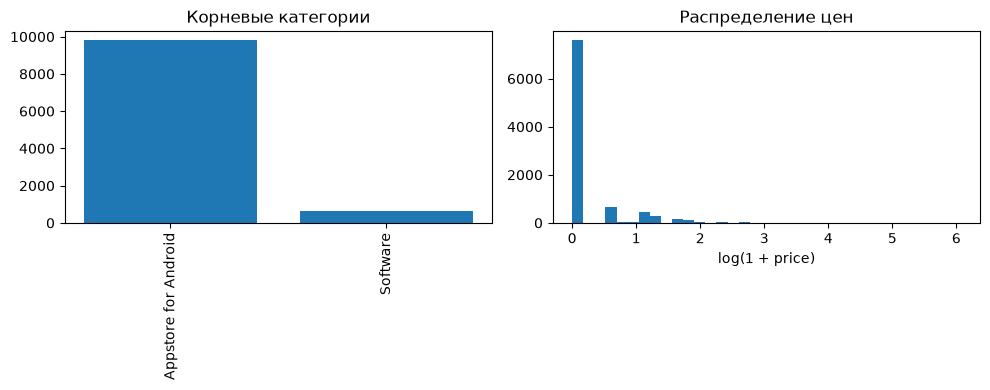

In [14]:
split, users, items = chronological_split(selected)
n_users, n_items = len(users), len(items)
train = split.filter(pl.col("split") == "train")
val = split.filter(pl.col("split") == "val")
test = split.filter(pl.col("split") == "test")
final_fit = split.filter(
    pl.col("split") != "test"
)  # train + val для финального обучения
split.write_parquet(DATA_DIR / "prepared/split.parquet")
display(
    split.group_by("split")
    .agg(
        pl.len().alias("rows"),
        pl.col("user_id").n_unique().alias("users"),
        pl.col("item_id").n_unique().alias("items"),
    )
    .sort("split")
)

metadata = load_metadata(items, DATA_DIR)
print(
    "Порядок метаданных совпадает с item_idx:",
    metadata["item_id"].to_list() == items.to_list(),
)
print("Без метаданных:", (~metadata["metadata_present"]).sum())
print("Без цены:", metadata["price"].null_count())
print("Пустые названия:", (metadata["title"] == "").sum())
print("Пустые описания:", (metadata["description"] == "").sum())
print("Категорий:", metadata["root_category"].n_unique())
display(metadata.select("item_id", "title", "root_category").head())

categories = metadata.group_by("root_category").len().sort("len", descending=True)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(categories["root_category"].to_list(), categories["len"].to_numpy())
axes[0].set(title="Корневые категории")
axes[0].tick_params(axis="x", labelrotation=90)
axes[1].hist(
    np.log1p(metadata["price"].drop_nulls().to_numpy()),
    35,
)
axes[1].set(title="Распределение цен", xlabel="log(1 + price)")
plt.tight_layout()
plt.show()

После фильтрации осталось 1200650 отзывов, 138866 пользователей и 10466 товаров.

В исходных данных у типичного пользователя всего одна оценка, так что фильтр убрал почти всех обычных пользователей, и выборка описывает более активных людей.

Корневых категорий всего две, а у 838 товаров нет цены. Категории получаются очень грубыми, поэтому много пользы от них ждать не стоит. Проверим это сравнением FM с вариантом только на ID.


## 5. Оценка рекомендаций

Схема следующая: при подборе настроек модель учится на train, а скрытый товар берётся из validation. В финале модель учится на train+validation, а скрытый товар берётся из test.

Кандидаты - все товары, которые есть в обучающей части, кроме уже оценённых пользователем (в том числе оценённых низко). Пользователь попадает в метрики, только если его скрытый товар известен модели и оценён на 4 или 5. Для нового пользователя модель выдала бы популярное, но в этих данных таких нет. Холодные товары исключены (отфильтрованы).

Основную метрику выбираем до подбора - NDCG@10. Дополнительная - Recall@10.

Скрытый релевантный товар у каждого пользователя один, поэтому:

- Recall@10 = 1, если товар в первых 10, иначе 0;
- NDCG@10 = $1 / \log_2(r+1)$, если место $r \leq 10$, иначе 0.

Метрики усредняем по пользователям. Recall отвечает на вопрос "нашли или нет", а NDCG поощряет более высокое место.

Ещё посмотрим на coverage - какая доля каталога вообще попала в рекомендации.

У всех моделей одни и те же пользователи, кандидаты и правила.

In [15]:
val_evaluation = prepare_evaluation(train, val, n_users, n_items, POSITIVE_RATING)
print("Validation:")
print(evaluation_report(val_evaluation, val))

rng = np.random.default_rng(SEED)
tuning_users = np.sort(rng.choice(n_users, min(TUNING_USERS, n_users), replace=False))
print("Пользователей для подбора:", len(tuning_users))
print(
    "Из них подходят для метрик:",
    len(np.intersect1d(tuning_users, val_evaluation["users"])),
)

print("Проверка метрик на известных позициях:")
for rank in [1, 2, 3, 10, 11]:
    print(
        f"Место {rank}: Recall={recall_at_k(rank, K):.0f}, NDCG={ndcg_at_k(rank, K):.3f}"
    )

Validation:
shape: (4, 2)
┌────────────────────┬──────────┐
│ показатель         ┆ значение │
│ ---                ┆ ---      │
│ str                ┆ i64      │
╞════════════════════╪══════════╡
│ пользователей      ┆ 138866   │
│ с оценкой ниже 4   ┆ 33763    │
│ с холодным товаром ┆ 12       │
│ участвуют в оценке ┆ 105096   │
└────────────────────┴──────────┘
Пользователей для подбора: 20000
Из них подходят для метрик: 15120
Проверка метрик на известных позициях:
Место 1: Recall=1, NDCG=1.000
Место 2: Recall=1, NDCG=0.631
Место 3: Recall=1, NDCG=0.500
Место 10: Recall=1, NDCG=0.289
Место 11: Recall=0, NDCG=0.000


## 6. Обучение и подбор настроек

Для каждой настройки модель учится на всём train. Чтобы подбор не тянулся слишком долго, на validation считаем метрики на одной фиксированной случайной выборке до `TUNING_USERS` пользователей. Из каждой сетки берём настройку с лучшим validation NDCG@10. Test здесь не используется.

У всех моделей одинаковый интерфейс: `model.fit(train, metadata=metadata)` и `model.recommend(user_idx, k=10)`.

Метаданные как признаки использует только FM, остальным они нужны лишь для размера каталога. Обучающий сигнал каждая модель строит себе сама внутри `fit`.

`BaseRecommender` запоминает уже оценённые товары и убирает их из выдачи. Для timeSVD++ время запроса передаётся как `timestamp` в миллисекундах; при оценке оно одно для всех кандидатов пользователя.

In [16]:
GRIDS = {
    "ItemKNN": {"k": [20, 50, 100], "lam": [0, 10, 50]},
    "iALS": {"n_factors": [16, 32], "alpha": [5, 20, 100], "lam": [0.01, 0.05]},
    "EASE": {"lam": [1, 10, 100, 500]},
    "FM": {"d": [8, 16], "l2": [0, 1e-5]},
    "timeSVD++": {"n_factors": [16, 32], "reg": [0.02, 0.05]},
}
best_params = {}
validation_runs = {}
if not TRAIN_MODELS:
    saved_validation = pl.read_csv(RESULTS_DIR / "validation.csv")
    print("Показан сохранённый подбор предыдущего обучающего запуска.")

from concurrent.futures import ThreadPoolExecutor, as_completed


def tune_model(name):
    if not TRAIN_MODELS:
        table = saved_validation.filter(pl.col("model") == name)
    else:
        grid = GRIDS[name]
        param_grid = [dict(zip(grid, values)) for values in product(*grid.values())]

        def evaluate(params):
            start = perf_counter()
            model = MODELS[name](**params)
            model.seed = SEED
            model.fit(train, metadata=metadata)
            fit_seconds = perf_counter() - start

            start = perf_counter()
            metrics, _ = ranking_metrics(model, val_evaluation, tuning_users, K)
            rank_seconds = perf_counter() - start

            print(name, params, "NDCG@10 =", round(metrics["NDCG@10"], 6))

            return {
                "model": name,
                "params": json.dumps(params, sort_keys=True),
                **metrics,
                "fit_seconds": fit_seconds,
                "rank_seconds": rank_seconds,
            }

        rows = [None] * len(param_grid)

        with ThreadPoolExecutor(max_workers=N_THREADS) as executor:
            futures = {
                executor.submit(evaluate, params): i
                for i, params in enumerate(param_grid)
            }

            for future in as_completed(futures):
                rows[futures[future]] = future.result()

        table = pl.DataFrame(rows)
        gc.collect()

    best = table.sort("NDCG@10", descending=True, maintain_order=True).row(
        0, named=True
    )

    params = json.loads(best["params"])
    print("Выбрано:", name, params)
    return params, table

### ItemKNN

Берём бинарную матрицу $X$: 1, если оценка 4-5, иначе 0. Сходство двух товаров считаем по пользователям, которым понравились оба (косинус со штрафом за малое число общих пользователей):

$$s_{ij}=\frac{n_{ij}}{\sqrt{n_i n_j}}\cdot\frac{n_{ij}}{n_{ij}+\lambda}.$$

Связи, где общих пользователей меньше трёх, убираем. Для каждого товара оставляем $k$ ближайших соседей. Балл кандидата — сумма его сходств с понравившимися товарами пользователя. Здесь $k$ - число соседей, а длина выдачи всегда 10.

In [17]:
best_params["ItemKNN"], validation_runs["ItemKNN"] = tune_model("ItemKNN")
display(validation_runs["ItemKNN"])

ItemKNN {'k': 20, 'lam': 0} NDCG@10 = 0.086727
ItemKNN {'k': 50, 'lam': 0} NDCG@10 = 0.090609
ItemKNN {'k': 50, 'lam': 50} NDCG@10 = 0.095411
ItemKNN {'k': 20, 'lam': 10} NDCG@10 = 0.090605
ItemKNN {'k': 20, 'lam': 50} NDCG@10 = 0.09197
ItemKNN {'k': 50, 'lam': 10} NDCG@10 = 0.094971
ItemKNN {'k': 100, 'lam': 50} NDCG@10 = 0.097465
ItemKNN {'k': 100, 'lam': 0} NDCG@10 = 0.093725
ItemKNN {'k': 100, 'lam': 10} NDCG@10 = 0.097165
Выбрано: ItemKNN {'k': 100, 'lam': 50}


model,params,NDCG@10,Recall@10,coverage,eligible_users,empty_candidates,fit_seconds,rank_seconds
str,str,f64,f64,f64,i64,i64,f64,f64
"""ItemKNN""","""{""k"": 20, ""lam"": 0}""",0.086727,0.15496,0.495172,15120,0,6.620652,16.434143
"""ItemKNN""","""{""k"": 20, ""lam"": 10}""",0.090605,0.162037,0.395066,15120,0,7.490824,16.50121
"""ItemKNN""","""{""k"": 20, ""lam"": 50}""",0.09197,0.16336,0.372024,15120,0,7.421687,16.664901
"""ItemKNN""","""{""k"": 50, ""lam"": 0}""",0.090609,0.162765,0.466966,15120,0,6.098856,17.264592
"""ItemKNN""","""{""k"": 50, ""lam"": 10}""",0.094971,0.170172,0.355483,15120,0,7.383032,17.11561
"""ItemKNN""","""{""k"": 50, ""lam"": 50}""",0.095411,0.170899,0.324888,15120,0,6.466223,17.496054
"""ItemKNN""","""{""k"": 100, ""lam"": 0}""",0.093725,0.169511,0.453676,15120,0,7.908504,16.868429
"""ItemKNN""","""{""k"": 100, ""lam"": 10}""",0.097165,0.175463,0.3377,15120,0,7.891578,16.896799
"""ItemKNN""","""{""k"": 100, ""lam"": 50}""",0.097465,0.17586,0.303566,15120,0,7.314384,17.393859


### iALS

Для каждого пользователя и товара учим эмбеддинги $x_u$ и $y_i$, балл - $x_u^T y_i$.

Берём $p_{ui}=1[rating\geq4]$, $c_{ui}=1+\alpha p_{ui}$ и минимизируем

$$\sum_{u,i}c_{ui}(p_{ui}-x_u^Ty_i)^2+\lambda(\|X\|_F^2+\|Y\|_F^2).$$

По очереди решаем линейные системы: сначала для пользователей, потом для товаров, всего 10 итераций. Положительные пары получают больший вес, а отсутствие оценки считается слабым сигналом, а не явным "не нравится".

In [18]:
best_params["iALS"], validation_runs["iALS"] = tune_model("iALS")
display(validation_runs["iALS"])

iALS, iteration 1/10
iALS, iteration 1/10
iALS, iteration 1/10
iALS, iteration 1/10
iALS, iteration 1/10
iALS, iteration 1/10
iALS, iteration 2/10
iALS, iteration 2/10
iALS, iteration 2/10
iALS, iteration 2/10
iALS, iteration 2/10
iALS, iteration 2/10
iALS, iteration 3/10
iALS, iteration 3/10
iALS, iteration 3/10
iALS, iteration 3/10
iALS, iteration 3/10
iALS, iteration 3/10
iALS, iteration 4/10
iALS, iteration 4/10
iALS, iteration 4/10
iALS, iteration 4/10
iALS, iteration 4/10
iALS, iteration 4/10
iALS, iteration 5/10
iALS, iteration 5/10
iALS, iteration 5/10
iALS, iteration 5/10
iALS, iteration 5/10
iALS, iteration 5/10
iALS, iteration 6/10
iALS, iteration 6/10
iALS, iteration 6/10
iALS, iteration 6/10
iALS, iteration 6/10
iALS, iteration 6/10
iALS, iteration 7/10
iALS, iteration 7/10
iALS, iteration 7/10
iALS, iteration 7/10
iALS, iteration 7/10
iALS, iteration 7/10
iALS, iteration 8/10
iALS, iteration 8/10
iALS, iteration 8/10
iALS, iteration 8/10
iALS, iteration 8/10iALS, iteratio

model,params,NDCG@10,Recall@10,coverage,eligible_users,empty_candidates,fit_seconds,rank_seconds
str,str,f64,f64,f64,i64,i64,f64,f64
"""iALS""","""{""alpha"": 5, ""lam"": 0.01, ""n_f…",0.078914,0.143783,0.025528,15120,0,118.553069,27.321297
"""iALS""","""{""alpha"": 5, ""lam"": 0.05, ""n_f…",0.078904,0.143783,0.025528,15120,0,118.608237,27.181088
"""iALS""","""{""alpha"": 20, ""lam"": 0.01, ""n_…",0.08033,0.148545,0.037671,15120,0,118.697756,27.222537
"""iALS""","""{""alpha"": 20, ""lam"": 0.05, ""n_…",0.08034,0.148545,0.037671,15120,0,118.335084,27.359272
"""iALS""","""{""alpha"": 100, ""lam"": 0.01, ""n…",0.076171,0.142394,0.07276,15120,0,118.382997,27.556578
"""iALS""","""{""alpha"": 100, ""lam"": 0.05, ""n…",0.076128,0.142328,0.072856,15120,0,118.714557,27.28423
"""iALS""","""{""alpha"": 5, ""lam"": 0.01, ""n_f…",0.078708,0.139352,0.040252,15120,0,368.819992,13.576583
"""iALS""","""{""alpha"": 5, ""lam"": 0.05, ""n_f…",0.07871,0.139352,0.040252,15120,0,369.305982,13.501199
"""iALS""","""{""alpha"": 20, ""lam"": 0.01, ""n_…",0.082177,0.148016,0.066737,15120,0,369.81765,13.306654


### EASE

Учим матрицу связей между товарами $B$:

$$\min_B\|X-XB\|_F^2+\lambda\|B\|_F^2,\qquad B_{ii}=0.$$

Для $Q=(X^TX+\lambda I)^{-1}$ решение выписывается явно: $B_{ij}=-Q_{ij}/Q_{jj}$ при $i\ne j$, диагональ нулевая.

Балл - элемент $XB$.

Нулевая диагональ нужна, чтобы товар не предсказывал сам себя. Матрица плотная, поэтому число товаров пришлось ограничить на этапе фильтрации.

In [19]:
best_params["EASE"], validation_runs["EASE"] = tune_model("EASE")
display(validation_runs["EASE"])

EASE {'lam': 1} NDCG@10 = 0.095
EASE {'lam': 10} NDCG@10 = 0.100057
EASE {'lam': 500} NDCG@10 = 0.10427
EASE {'lam': 100} NDCG@10 = 0.105728
Выбрано: EASE {'lam': 100}


model,params,NDCG@10,Recall@10,coverage,eligible_users,empty_candidates,fit_seconds,rank_seconds
str,str,f64,f64,f64,i64,i64,f64,f64
"""EASE""","""{""lam"": 1}""",0.095,0.165675,0.590687,15120,0,20.776794,22.491608
"""EASE""","""{""lam"": 10}""",0.100057,0.174339,0.481021,15120,0,28.321361,20.701149
"""EASE""","""{""lam"": 100}""",0.105728,0.187632,0.323167,15120,0,41.727516,12.220605
"""EASE""","""{""lam"": 500}""",0.10427,0.186243,0.269051,15120,0,32.943184,18.290002


### FM с метапризнаками

$$f(x)=w_0+\sum_jw_jx_j+\sum_{j<l}\langle v_j,v_l\rangle x_jx_l.$$

Признаки:
- ID пользователя и товара;
- категория товара;
- log(популярность и средняя оценка товара);
- log(активность пользователя);
- главная категория пользователя и её доля в его положительной истории.

Идея в том, чтобы добавить к ID то, что известно в момент рекомендации.

Числовые признаки стандартизируем, а все статистики считаем только по обучающей части. Категорию считаем постоянным свойством товара. Цену не берём (потому что неактуальна).

Обучение: BCE, Adam, 5 эпох, batch=1024, lr=0.02.

К каждой положительной паре берём три случайных тёплых товара, которых пользователь не оценивал. Конечно, неоценённый товар не обязательно плохой, это лишь приближение.

In [20]:
best_params["FM"], validation_runs["FM"] = tune_model("FM")
display(validation_runs["FM"])

FM, эпоха 1/5
FM, эпоха 1/5
FM, эпоха 1/5
FM, эпоха 1/5
FM, эпоха 2/5
FM, эпоха 2/5
FM, эпоха 2/5
FM, эпоха 2/5
FM, эпоха 3/5
FM, эпоха 3/5
FM, эпоха 3/5
FM, эпоха 3/5
FM, эпоха 4/5
FM, эпоха 4/5
FM, эпоха 4/5
FM, эпоха 4/5
FM, эпоха 5/5
FM, эпоха 5/5
FM, эпоха 5/5
FM, эпоха 5/5
FM {'d': 8, 'l2': 0} NDCG@10 = 0.020877
FM {'d': 8, 'l2': 1e-05} NDCG@10 = 0.030585
FM {'d': 16, 'l2': 0} NDCG@10 = 0.01872
FM {'d': 16, 'l2': 1e-05} NDCG@10 = 0.029617
Выбрано: FM {'d': 8, 'l2': 1e-05}


model,params,NDCG@10,Recall@10,coverage,eligible_users,empty_candidates,fit_seconds,rank_seconds
str,str,f64,f64,f64,i64,i64,f64,f64
"""FM""","""{""d"": 8, ""l2"": 0}""",0.020877,0.042923,0.208529,15120,0,197.643451,17.236411
"""FM""","""{""d"": 8, ""l2"": 1e-05}""",0.030585,0.063095,0.005928,15120,0,204.581732,14.497635
"""FM""","""{""d"": 16, ""l2"": 0}""",0.01872,0.039484,0.40348,15120,0,211.892957,11.065804
"""FM""","""{""d"": 16, ""l2"": 1e-05}""",0.029617,0.058995,0.007362,15120,0,212.514513,10.772795


### timeSVD++

Здесь учимся на исходных оценках 1-5 и минимизируем квадрат ошибки с регуляризацией:

$$\hat r_{ui}(t)=\mu+b_u+b_i+\alpha_u dev_u(t)+b_{u,bin(t)}
+q_i^T\left(p_u+a_u dev_u(t)+\frac{1}{\sqrt{|N_u|}}\sum_{j\in N_u}y_j\right).$$

$N_u$ — товары, которым пользователь в train поставил 4-5, а $dev_u(t)=sign(t-\bar t_u)|t-\bar t_u|^{0.4}$, где время в днях.

Историю делим на 5 временных интервалов по квантилям, все временные статистики считаем по fit.

Вектор $a_u$ отвечает за то, как вкусы пользователя меняются со временем. Чисто пользовательские смещения порядок товаров для одного пользователя не меняют.

Параметры: 10 эпох, lr=0.005, для дрейфа шаг в 100 раз меньше.

Время запроса при оценке - время скрытого события, одинаковое для всех кандидатов.

In [21]:
best_params["timeSVD++"], validation_runs["timeSVD++"] = tune_model("timeSVD++")
display(validation_runs["timeSVD++"])

validation = pl.concat(list(validation_runs.values()))
if TRAIN_MODELS:
    validation.write_csv(RESULTS_DIR / "validation.csv")
print("Всего конфигураций:", len(validation))
display(pl.DataFrame([
    {"model": name, "params": json.dumps(params)} for name, params in best_params.items()
]))

timeSVD++, эпоха 1/10
timeSVD++, эпоха 1/10
timeSVD++, эпоха 1/10
timeSVD++, эпоха 1/10
timeSVD++, эпоха 2/10
timeSVD++, эпоха 2/10
timeSVD++, эпоха 2/10
timeSVD++, эпоха 2/10
timeSVD++, эпоха 3/10
timeSVD++, эпоха 3/10
timeSVD++, эпоха 4/10
timeSVD++, эпоха 3/10
timeSVD++, эпоха 3/10
timeSVD++, эпоха 4/10
timeSVD++, эпоха 5/10
timeSVD++, эпоха 5/10
timeSVD++, эпоха 4/10
timeSVD++, эпоха 4/10
timeSVD++, эпоха 6/10
timeSVD++, эпоха 6/10
timeSVD++, эпоха 5/10
timeSVD++, эпоха 5/10
timeSVD++, эпоха 7/10
timeSVD++, эпоха 7/10
timeSVD++, эпоха 6/10
timeSVD++, эпоха 8/10
timeSVD++, эпоха 6/10
timeSVD++, эпоха 8/10
timeSVD++, эпоха 9/10
timeSVD++, эпоха 9/10
timeSVD++, эпоха 7/10
timeSVD++, эпоха 7/10
timeSVD++, эпоха 10/10
timeSVD++, эпоха 10/10
timeSVD++, эпоха 8/10
timeSVD++, эпоха 8/10
timeSVD++ {'n_factors': 16, 'reg': 0.02} NDCG@10 = 0.007962
timeSVD++ {'n_factors': 16, 'reg': 0.05} NDCG@10 = 0.00919
timeSVD++, эпоха 9/10
timeSVD++, эпоха 9/10
timeSVD++, эпоха 10/10
timeSVD++, эпоха 10/

model,params,NDCG@10,Recall@10,coverage,eligible_users,empty_candidates,fit_seconds,rank_seconds
str,str,f64,f64,f64,i64,i64,f64,f64
"""timeSVD++""","""{""n_factors"": 16, ""reg"": 0.02}""",0.007962,0.016534,0.014724,15120,0,358.23993,25.564984
"""timeSVD++""","""{""n_factors"": 16, ""reg"": 0.05}""",0.00919,0.019709,0.008318,15120,0,358.983137,25.357308
"""timeSVD++""","""{""n_factors"": 32, ""reg"": 0.02}""",0.007058,0.01422,0.013768,15120,0,405.114322,10.587664
"""timeSVD++""","""{""n_factors"": 32, ""reg"": 0.05}""",0.00952,0.019444,0.009179,15120,0,404.959763,10.682343


Всего конфигураций: 33


model,params
str,str
"""ItemKNN""","""{""k"": 100, ""lam"": 50}"""
"""iALS""","""{""alpha"": 20, ""lam"": 0.01, ""n_…"
"""EASE""","""{""lam"": 100}"""
"""FM""","""{""d"": 8, ""l2"": 1e-05}"""
"""timeSVD++""","""{""n_factors"": 32, ""reg"": 0.05}"""


## 7. Финальное сравнение

Настройки выбраны по validation. Теперь каждую модель обучаем заново на train+validation (признаки и статистики пересчитываются) и только после этого смотрим test.

Заодно сравним FM с вариантом без метапризнаков (только ID) и timeSVD++ с вариантом без времени. В каждой паре настройки и seed одинаковые, меняется только одно: есть ли
метаданные или временные компоненты.

Test:
shape: (4, 2)
┌────────────────────┬──────────┐
│ показатель         ┆ значение │
│ ---                ┆ ---      │
│ str                ┆ i64      │
╞════════════════════╪══════════╡
│ пользователей      ┆ 138866   │
│ с оценкой ниже 4   ┆ 34016    │
│ с холодным товаром ┆ 98       │
│ участвуют в оценке ┆ 104771   │
└────────────────────┴──────────┘
ItemKNN {'NDCG@10': np.float64(0.09612581263760128), 'Recall@10': np.float64(0.1711065084804001), 'coverage': np.float64(0.4334320940456848), 'eligible_users': 104771, 'empty_candidates': 0}
iALS, iteration 1/10
iALS, iteration 2/10
iALS, iteration 3/10
iALS, iteration 4/10
iALS, iteration 5/10
iALS, iteration 6/10
iALS, iteration 7/10
iALS, iteration 8/10
iALS, iteration 9/10
iALS, iteration 10/10
iALS {'NDCG@10': np.float64(0.0829193890005713), 'Recall@10': np.float64(0.1491634135400063), 'coverage': np.float64(0.07196788683933862), 'eligible_users': 104771, 'empty_candidates': 0}
EASE {'NDCG@10': np.float64(0.10493363432875187), 

model,NDCG@10,Recall@10,coverage,params,fit_seconds
str,f64,f64,f64,str,f64
"""ItemKNN""",0.096126,0.171107,0.433432,"""{""k"": 100, ""lam"": 50}""",1.691711
"""iALS""",0.082919,0.149163,0.071968,"""{""alpha"": 20, ""lam"": 0.01, ""n_…",21.926603
"""EASE""",0.104934,0.185567,0.476919,"""{""lam"": 100}""",7.085498
"""FM""",0.030918,0.059043,0.005926,"""{""d"": 8, ""l2"": 1e-05}""",55.265181
"""timeSVD++""",0.012359,0.025541,0.009462,"""{""n_factors"": 32, ""reg"": 0.05}""",68.988367


Одинаковое число пользователей у всех моделей: True
Пустых списков кандидатов: 0


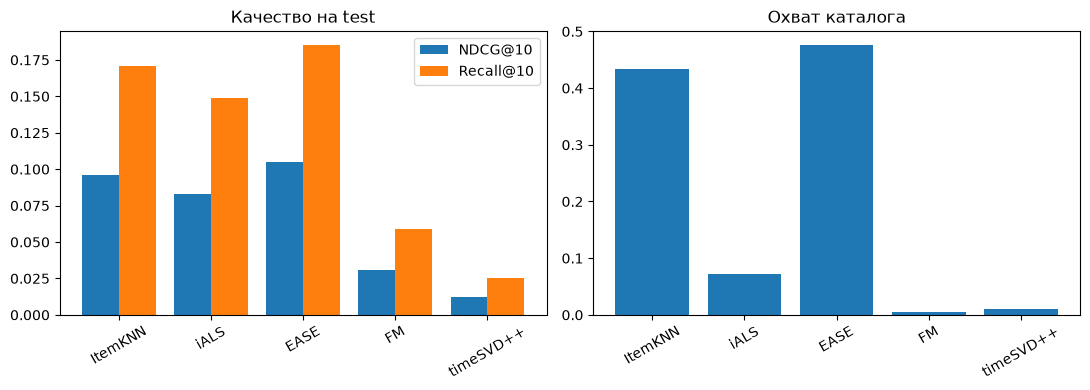

In [22]:
test_evaluation = prepare_evaluation(final_fit, test, n_users, n_items, POSITIVE_RATING)
print("Test:")
print(evaluation_report(test_evaluation, test))

if TRAIN_MODELS:
    MODEL_DIR.mkdir(parents=True, exist_ok=True)
    # (название, класс, чьи настройки берём, что меняем)
    runs = [(name, cls, name, {}) for name, cls in MODELS.items()]
    for name, (cls, parent, change) in ABLATIONS.items():
        runs.append((name, cls, parent, change))

    rows = []
    for name, cls, parent, change in runs:
        params = best_params[parent]
        start = perf_counter()
        model = cls(**params, **change)
        model.seed = SEED
        model.fit(final_fit, metadata=metadata)
        fit_seconds = perf_counter() - start
        with (MODEL_DIR / f"{name}.pkl").open("wb") as file:
            pickle.dump(model, file)

        start = perf_counter()
        metrics, _ = ranking_metrics(model, test_evaluation, k=K)
        rows.append(
            {
                "model": name,
                "params": json.dumps(params, sort_keys=True),
                **metrics,
                "fit_seconds": fit_seconds,
                "rank_seconds": perf_counter() - start,
            }
        )
        print(name, metrics)
        del model
        gc.collect()

    all_results = pl.DataFrame(rows)
    all_results.write_csv(RESULTS_DIR / "test_with_ablations.csv")
    all_results.filter(pl.col("model").is_in(MODEL_NAMES)).write_csv(
        RESULTS_DIR / "test.csv"
    )
    (RESULTS_DIR / "hyperparameters.json").write_text(
        json.dumps(
            {
                "seed": SEED,
                "K": K,
                "primary_metric": "NDCG@10",
                "best_params": best_params,
            },
            indent=2,
        )
    )
else:
    print("Результаты предыдущего полного обучения на этом компе:")
    all_results = pl.read_csv(RESULTS_DIR / "test_with_ablations.csv")

test_table = all_results.filter(pl.col("model").is_in(MODEL_NAMES))
display(
    test_table.select(
        "model", "NDCG@10", "Recall@10", "coverage", "params", "fit_seconds"
    )
)
print(
    "Одинаковое число пользователей у всех моделей:",
    all_results["eligible_users"].n_unique() == 1,
)
print("Пустых списков кандидатов:", all_results["empty_candidates"].sum())

x = np.arange(len(test_table))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(x - 0.2, test_table["NDCG@10"].to_numpy(), width=0.4, label="NDCG@10")
axes[0].bar(x + 0.2, test_table["Recall@10"].to_numpy(), width=0.4, label="Recall@10")
axes[0].set(title="Качество на test")
axes[0].legend()
axes[1].bar(x, test_table["coverage"].to_numpy())
axes[1].set(title="Охват каталога")
for ax in axes:
    ax.set_xticks(x, test_table["model"].to_list(), rotation=30)
plt.tight_layout()
plt.show()

## 8. Влияние признаков и ход обучения

Посмотрим на разницу метрик внутри пар: что дали метаданные в FM и время в timeSVD++. Кривые потерь разных моделей не сравниваем, потому что функции потерь у них разные.

У ItemKNN и EASE итераций нет, так что и кривых нет.

In [23]:
display(
    all_results.filter(
        pl.col("model").is_in(["FM", "FM-ID", "timeSVD++", "SVD++-static"])
    ).select("model", "NDCG@10", "Recall@10", "coverage")
)

res = {row["model"]: row for row in all_results.iter_rows(named=True)}
metrics_to_compare = ["NDCG@10", "Recall@10", "coverage"]
deltas = pl.DataFrame(
    [
        {
            "comparison": "FM - FM-ID",
            **{m: res["FM"][m] - res["FM-ID"][m] for m in metrics_to_compare},
        },
        {
            "comparison": "timeSVD++ - static SVD++",
            **{
                m: res["timeSVD++"][m] - res["SVD++-static"][m]
                for m in metrics_to_compare
            },
        },
    ]
)
display(deltas)
if TRAIN_MODELS:
    deltas.write_csv(RESULTS_DIR / "ablation_deltas.csv")

model,NDCG@10,Recall@10,coverage
str,f64,f64,f64
"""FM""",0.030918,0.059043,0.005926
"""timeSVD++""",0.012359,0.025541,0.009462
"""FM-ID""",0.034001,0.068053,0.002485
"""SVD++-static""",0.012301,0.025484,0.009271


comparison,NDCG@10,Recall@10,coverage
str,f64,f64,f64
"""FM - FM-ID""",-0.003082,-0.00901,0.003441
"""timeSVD++ - static SVD++""",0.000058,0.000057,0.000191


## 9. Пример рекомендаций

Загрузим сохранённую EASE и посмотрим, что она советует одному пользователю (названия товаров). Уже оценённые им товары в выдачу попасть не должны.

In [24]:
model_path = MODEL_DIR / "EASE.pkl"
if model_path.exists():
    with model_path.open("rb") as file:
        model = pickle.load(file)
    user = 0
    top = model.recommend(user, k=K)
    recommendation_table = metadata.gather(top.tolist()).select(
        "title", "root_category"
    )
    recommendation_table = recommendation_table.with_row_index("место", offset=1)
    display(recommendation_table)
    print("Рекомендовано товаров:", len(top))
    print("Уже оценённых среди рекомендаций:", model.seen[user, top].sum())
    del model
else:
    print("Для примера с названиями нужно сначала обучить модели: TRAIN_MODELS = True.")

место,title,root_category
u32,str,str
1,"""Candy Crush Saga""","""Appstore for Android"""
2,"""Stack the Countries""","""Appstore for Android"""
3,"""Minion Rush: Running game""","""Appstore for Android"""
4,"""Flow Free""","""Appstore for Android"""
5,"""Solitaire""","""Appstore for Android"""
6,"""Crossy Road""","""Appstore for Android"""
7,"""Solitaire""","""Appstore for Android"""
8,"""Escape The Titanic""","""Appstore for Android"""
9,"""Bingo""","""Appstore for Android"""


Рекомендовано товаров: 10
Уже оценённых среди рекомендаций: 0


## 10. Выводы

Лучше всех сработала EASE с $\lambda=100$: NDCG@10 = 0,104934, Recall@10 = 0,185567. То есть скрытый товар попал в топ-10 примерно у 18,6% пользователей. На втором месте ItemKNN с NDCG@10 = 0,096126, на третьем iALS с 0,082919. По охвату EASE тоже первая: в рекомендации попало около 47,7% тёплого каталога. У ItemKNN получилось 43,3%, а у iALS - только 7,2%.

Дополнительные признаки в FM не помогли. С ними NDCG@10 = 0,030918, а только на ID - 0,034001. Охват с метапризнаками немного выше, но нужные товары находятся реже. Категории здесь очень грубые (их всего две), так что много информации они не добавляют. Правда, FM получала ещё и статистики пользователей и товаров, поэтому списывать весь результат только на категории нельзя.

Время в timeSVD++ почти ничего не изменило: NDCG@10 вырос с 0,012301 до 0,012359. Разница около 0,000058, по Recall тоже почти без изменений. Значимость этой разницы не проверяли, так что делать вывод о пользе временных признаков пока рано.

В целом на этой выборке лучше получилось использовать связи между товарами. FM и timeSVD++ заметно отстали, хотя устроены сложнее. Возможно, им не хватило подбора настроек или числа эпох, а короткие истории пользователей тоже не помогают. Но отдельно это не проверяли. Пока можно сказать только, что при выбранных настройках они проиграли EASE и ItemKNN.

В примере EASE выдала десять товаров, уже оценённых среди них нет. Значит, фильтр истории для этого пользователя работает. Сам список в основном состоит из игр, но по одному примеру судить о качестве сложно - для этого и считали метрики на всём test.

Для этой задачи я бы оставил EASE: у неё лучшие метрики и самый большой охват. Правда, она хранит плотную матрицу связей между товарами, и на гораздо большем каталоге с памятью уже могут быть проблемы.
